# 05 · Evaluación: indicadores de tráfico

## Motivación / Objetivos

Traducir las detecciones a **indicadores de tráfico** útiles para el control semafórico, por cámara, por franja horaria y por contexto (tipo de día, iluminación y clima).

Bloques de indicadores:

**1. Tráfico**
- Vehículos y peatones medios por imagen (ocupación instantánea; con imágenes fijas no se puede medir un flujo por minuto sin seguir objetos entre fotogramas).
- Fracción del tiempo en rojo / ámbar / verde del semáforo vehicular.
- Duración media de las fases verde y roja (solo si el refresco medido lo permite).

**2. Comportamiento**
- Peatones esperando con el semáforo peatonal en rojo / cruzando en verde.
- Vehículos acumulados con el semáforo vehicular en rojo frente a verde (cola estimada).

**3. Eficiencia**
- Tiempo medio de espera (si se pueden medir duraciones).
- Densidad vehicular y ratio peatón/vehículo.

**Objetivos del TFM relacionados:** OE-4 (estado y tiempos de los semáforos), OE-5 (relación entre peatones, vehículos y semáforos) y OE-7 (comportamiento por contexto).

## Método

Se unen las fases del preprocesamiento por `(camera, image)`: `frames` (contexto temporal e iluminación) + `weather` + `detections` (conteos y estado de los semáforos), **solo de las 24 cámaras del servicio**.

**Duraciones de fase.** Un ciclo semafórico dura ~60–120 s. Las duraciones solo se calculan si el refresco medido en `00b` es ≤ `max_refresco_para_duraciones_s`, y las rachas se cortan cuando el hueco entre dos imágenes consecutivas supera `max_hueco_racha_s` (`config.yaml` → `evaluacion`). Se descartan las rachas censuradas al inicio o al final de la serie. Si no se cumplen las condiciones, se informa la **fracción de tiempo** en cada estado, que sí es estimable con muestras de fase aleatoria.

1. Carga de datos y configuración.
2. Estado del semáforo por fotograma.
3. Indicadores por cámara.
4. Indicadores por franja horaria y por contexto.
5. Visualizaciones.
6. Exportación de los indicadores.

### 1. Carga de datos y configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import load_config, path
from deteccion import VEHICLE_CLASSES
from pipeline import load_frames, measured_refresh_s, only_service_cameras

CFG = load_config()["evaluacion"]
RESULTS_DIR = path("resultados")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

frames = load_frames("weather", "detections")
if "n_vehiculos" not in frames.columns:
    raise RuntimeError("Falta la fase detections: ejecuta antes 02c_preproceso_deteccion_yolo26.ipynb")
frames = frames.dropna(subset=["n_vehiculos"])

# Solo las 24 cámaras del servicio de captura: las demás tienen 1-2 imágenes (instantáneas de 00)
n_total, cams_total = len(frames), frames["camera"].nunique()
frames = only_service_cameras(frames).sort_values(["camera", "timestamp"]).reset_index(drop=True)
print(f"Cámaras del servicio: {frames['camera'].nunique()} de {cams_total} | fotogramas: {len(frames)} de {n_total}")

REFRESH_S = measured_refresh_s()
DURATIONS_OK = REFRESH_S is not None and REFRESH_S <= CFG["max_refresco_para_duraciones_s"]
MAX_GAP_S = CFG["max_hueco_racha_s"]

print(f"Fotogramas: {len(frames)} | Cámaras: {frames['camera'].nunique()}")
print(f"Refresco medido: {REFRESH_S if REFRESH_S is not None else 'sin medición (ejecuta 00b)'} s")
print(f"Duraciones de fase: {'se calculan' if DURATIONS_OK else 'NO (se usan fracciones de tiempo)'}")

Cámaras del servicio: 24 de 133 | fotogramas: 74236 de 74454
Fotogramas: 74236 | Cámaras: 24
Refresco medido: 6.0 s
Duraciones de fase: se calculan


### 2. Estado del semáforo por fotograma

Con varios semáforos en la imagen, el estado es el color común a todos. Si hay colores distintos, el fotograma se marca como `mixto` y no se usa para los indicadores de estado.

In [2]:
def light_state(row, prefix, colors):
    present = [c for c in colors if row.get(f"n_{prefix}_{c}", 0) > 0]
    if not present:
        return None
    return present[0] if len(present) == 1 else "mixto"


frames["vehicle_light"] = frames.apply(lambda r: light_state(r, "traffic_light", ["red", "yellow", "green"]), axis=1)
frames["pedestrian_light"] = frames.apply(lambda r: light_state(r, "pedestrian_light", ["red", "green"]), axis=1)

print("Estado semáforo vehicular:")
print(frames["vehicle_light"].value_counts(dropna=False))
print("\nEstado semáforo peatonal:")
print(frames["pedestrian_light"].value_counts(dropna=False))

Estado semáforo vehicular:
vehicle_light
NaN       59186
yellow    14596
red         232
mixto       140
green        82
Name: count, dtype: int64

Estado semáforo peatonal:
pedestrian_light
NaN      72768
red       1314
green      153
mixto        1
Name: count, dtype: int64


In [3]:
def run_durations(g, column, state, max_gap_s):
    """Duraciones (s) de las rachas completas de `state` usando los timestamps reales.

    Una racha empieza en la primera imagen con ese estado y termina en la primera con otro
    estado. Se descartan las rachas cortadas por un hueco > max_gap_s y las censuradas
    (al principio o al final de la serie), porque su duración real es desconocida.
    """
    durations = []
    start = None
    prev_ts = None
    prev_state = None
    for ts, s in zip(g["timestamp"], g[column]):
        if prev_ts is not None and (ts - prev_ts).total_seconds() > max_gap_s:
            # Hueco: la racha en curso queda incompleta y la transición siguiente no se ha observado
            start = None
            prev_state = None
        elif start is not None and s != state:
            durations.append((ts - start).total_seconds())
            start = None
        if s == state and start is None and prev_state is not None and prev_state != state:
            start = ts  # solo rachas cuyo inicio se ha observado (transición desde otro estado conocido)
        prev_ts, prev_state = ts, s
    return durations


def state_fractions(g, column, colors):
    known = g[column].isin(colors)
    if not known.any():
        return {f"frac_{c}": np.nan for c in colors}
    return {f"frac_{c}": float((g.loc[known, column] == c).mean()) for c in colors}

### 3. Indicadores por cámara

In [4]:
def camera_indicators(g):
    red = g["vehicle_light"] == "red"
    green = g["vehicle_light"] == "green"
    ped_red = g["pedestrian_light"] == "red"
    ped_green = g["pedestrian_light"] == "green"

    row = {
        "n_frames": len(g),
        # Tráfico
        "vehiculos_medios_por_imagen": g["n_vehiculos"].mean(),
        "vehiculos_p90_por_imagen": g["n_vehiculos"].quantile(0.9),
        "peatones_medios_por_imagen": g["n_pedestrian"].mean(),
        **state_fractions(g, "vehicle_light", ["red", "yellow", "green"]),
        # Comportamiento
        "peatones_esperando_rojo": g.loc[ped_red, "n_pedestrian"].mean() if ped_red.any() else np.nan,
        "peatones_cruzando_verde": g.loc[ped_green, "n_pedestrian"].mean() if ped_green.any() else np.nan,
        "vehiculos_acumulados_rojo": g.loc[red, "n_vehiculos"].mean() if red.any() else np.nan,
        "vehiculos_en_verde": g.loc[green, "n_vehiculos"].mean() if green.any() else np.nan,
        # Eficiencia
        "densidad_vehicular": g["n_vehiculos"].mean(),
        "ratio_peaton_vehiculo": g["n_pedestrian"].sum() / g["n_vehiculos"].sum() if g["n_vehiculos"].sum() else np.nan,
    }

    if DURATIONS_OK:
        verdes = run_durations(g, "vehicle_light", "green", MAX_GAP_S)
        rojas = run_durations(g, "vehicle_light", "red", MAX_GAP_S)
        espera = run_durations(g.assign(_espera=np.where(red & (g["n_pedestrian"] > 0), "espera", "otro")), "_espera", "espera", MAX_GAP_S)
        row.update({
            "duracion_verde_media_s": np.mean(verdes) if verdes else np.nan,
            "duracion_roja_media_s": np.mean(rojas) if rojas else np.nan,
            "n_fases_medidas": len(verdes) + len(rojas),
            "tiempo_medio_espera_s": np.mean(espera) if espera else np.nan,
        })
    return pd.Series(row)


camera_df = frames.groupby("camera").apply(camera_indicators, include_groups=False).reset_index()
display(camera_df)

print("=== Agregado global (media por cámara) ===")
display(camera_df.drop(columns=["camera"]).mean().to_frame("media"))

,camera,n_frames,vehiculos_medios_por_imagen,vehiculos_p90_por_imagen,peatones_medios_por_imagen,frac_red,frac_yellow,frac_green,peatones_esperando_rojo,peatones_cruzando_verde,vehiculos_acumulados_rojo,vehiculos_en_verde,densidad_vehicular,ratio_peaton_vehiculo,duracion_verde_media_s,duracion_roja_media_s,n_fases_medidas,tiempo_medio_espera_s
0,21541,2829.0,6.680452,10.0,0.804525,0.001379,0.998621,0.000000,0.214286,0.545455,3.666667,NaN,6.680452,0.120430,NaN,NaN,0.0,NaN
1,21545,3627.0,6.640199,13.0,0.201268,0.000000,1.000000,0.000000,0.500000,NaN,NaN,NaN,6.640199,0.030311,NaN,NaN,0.0,NaN
2,21547,3811.0,13.996326,23.0,0.262661,0.010441,0.989559,0.000000,0.162879,0.000000,19.111111,NaN,13.996326,0.018766,NaN,NaN,0.0,NaN
3,21554,2689.0,3.775009,8.0,0.606917,0.057692,0.942308,0.000000,0.750000,NaN,8.333333,NaN,3.775009,0.160772,NaN,NaN,0.0,NaN
4,21556,3126.0,3.030070,6.0,1.929303,0.117771,0.872766,0.009464,2.439024,0.272727,2.616071,1.666667,3.030070,0.636719,NaN,NaN,0.0,NaN
5,21560,3883.0,9.686325,19.0,2.583312,0.009709,0.990291,0.000000,NaN,NaN,8.250000,NaN,9.686325,0.266697,NaN,NaN,0.0,NaN
6,21563,3940.0,4.929695,9.0,6.260152,0.000868,0.967882,0.031250,6.090909,NaN,8.000000,6.194444,4.929695,1.269886,10.375,NaN,8.0,NaN
7,21564,3105.0,4.133977,8.0,2.934300,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,4.133977,0.709801,NaN,NaN,0.0,NaN
8,21568,3122.0,2.322550,6.0,0.162716,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.322550,0.070059,NaN,NaN,0.0,NaN
9,21573,2872.0,4.420265,9.0,0.472841,0.020022,0.979978,0.000000,0.100000,NaN,1.277778,NaN,4.420265,0.106971,NaN,NaN,0.0,NaN


=== Agregado global (media por cámara) ===


,media
n_frames,3093.166667
vehiculos_medios_por_imagen,7.528474
vehiculos_p90_por_imagen,13.125000
peatones_medios_por_imagen,1.118317
frac_red,0.025063
frac_yellow,0.970698
frac_green,0.004239
peatones_esperando_rojo,1.050964
peatones_cruzando_verde,0.830754
vehiculos_acumulados_rojo,8.399749


### 4. Indicadores por franja horaria y por contexto

Los mismos indicadores (sin duraciones, que requieren series continuas por cámara) desglosados por franja horaria, tipo de día, iluminación y clima.

**Se calculan primero por cámara y después se promedian entre cámaras** (`by_camera_then_mean`), para que cada cámara pese lo mismo. Si se agregaran todos los fotogramas juntos, las 5 cámaras de referencia, capturadas cada 6 s en hora punta (unas 5 veces más fotogramas), dominarían el resultado. `n_frames` es la suma de fotogramas y `n_camaras` el número de cámaras que aportan a cada grupo.

In [5]:
def static_indicators(g):
    red = g["vehicle_light"] == "red"
    return pd.Series({
        "n_frames": len(g),
        "vehiculos_medios_por_imagen": g["n_vehiculos"].mean(),
        "peatones_medios_por_imagen": g["n_pedestrian"].mean(),
        **state_fractions(g, "vehicle_light", ["red", "yellow", "green"]),
        "vehiculos_acumulados_rojo": g.loc[red, "n_vehiculos"].mean() if red.any() else np.nan,
        "ratio_peaton_vehiculo": g["n_pedestrian"].sum() / g["n_vehiculos"].sum() if g["n_vehiculos"].sum() else np.nan,
    })


def by_camera_then_mean(df, col):
    """Indicadores por (grupo, cámara) y media entre cámaras: cada cámara pesa lo mismo."""
    per_camera = df.groupby([col, "camera"]).apply(static_indicators, include_groups=False).reset_index()
    result = per_camera.drop(columns=["camera"]).groupby(col).mean(numeric_only=True)
    result["n_frames"] = per_camera.groupby(col)["n_frames"].sum()
    result["n_camaras"] = per_camera.groupby(col)["camera"].nunique()
    return result.reset_index()


slot_df = by_camera_then_mean(frames, "time_slot_2h")
display(slot_df)

context_cols = [c for c in ["day_type", "illumination", "weather"] if c in frames.columns]
context_df = pd.concat(
    [by_camera_then_mean(frames, col).rename(columns={col: "valor"}).assign(contexto=col) for col in context_cols],
    ignore_index=True,
)
display(context_df.set_index(["contexto", "valor"]))

,time_slot_2h,n_frames,vehiculos_medios_por_imagen,peatones_medios_por_imagen,frac_red,frac_yellow,frac_green,vehiculos_acumulados_rojo,ratio_peaton_vehiculo,n_camaras
0,00:00-02:00,1413.0,2.962386,0.096143,0.250000,0.722222,0.027778,1.250000,0.093710,19
1,02:00-04:00,2091.0,3.199498,0.037244,0.218750,0.718750,0.062500,0.368056,0.071141,22
2,04:00-06:00,2093.0,3.167150,0.036938,0.285714,0.714286,0.000000,0.694444,0.038080,19
3,06:00-08:00,3450.0,5.695221,0.558643,0.348878,0.630450,0.020672,4.175245,0.149725,23
4,08:00-10:00,3247.0,7.459271,1.082581,0.045833,0.953376,0.000791,2.181818,0.222780,24
5,10:00-12:00,6964.0,8.684636,1.711148,0.015996,0.972184,0.011820,14.250000,0.259068,24
6,12:00-14:00,12446.0,9.394205,1.643321,0.024795,0.970870,0.004334,7.196970,0.213530,24
7,14:00-16:00,13564.0,8.982088,1.263407,0.071390,0.927793,0.000817,10.138889,0.177030,24
8,16:00-18:00,7612.0,7.272963,0.809990,0.026003,0.965643,0.008354,6.159420,0.135486,24
9,18:00-20:00,16560.0,6.906599,0.991607,0.082568,0.916633,0.000798,10.371324,0.178221,24


n_frames  vehiculos_medios_por_imagen  \
contexto     valor                                                  
day_type     fin_de_semana   16830.0                     9.167012   
             laborable       57406.0                     6.977026   
illumination crepusculo        561.0                     8.403629   
             dia             61356.0                     8.187050   
             noche           12319.0                     4.190891   
weather      sunny           57176.0                     6.986209   
             unknown         17060.0                     9.102615   

                            peatones_medios_por_imagen  frac_red  frac_yellow  \
contexto     valor                                                              
day_type     fin_de_semana                    1.630013  0.035748     0.960901   
             laborable                        0.947250  0.026763     0.969753   
illumination crepusculo                       1.493037  0.085897     0.908974   
             dia                              1.262314  0.019302     0.976895   
             noche                            0.425791  0.167667     0.819059   
weather      sunny                            0.949477  0.026766     0.969904   
             unknown                          1.612723  0.033365     0.963160   

                            frac_green  vehiculos_acumulados_rojo  \
contexto     valor                                                  
day_type     fin_de_semana    0.003351                   8.647343   
             laborable        0.003484                   7.954337   
illumination crepusculo       0.005128                  10.857143   
             dia              0.003802                  10.062338   
             noche            0.013274                   3.544444   
weather      sunny            0.003330                   7.954337   
             unknown          0.003475                   8.647343   

                            ratio_peaton_vehiculo  n_camaras  
contexto     valor                                            
day_type     fin_de_semana               0.231250         24  
             laborable                   0.171578         24  
illumination crepusculo                  0.243928         24  
             dia                         0.190750         24  
             noche                       0.147876         24  
weather      sunny                       0.171586         24  
             unknown                     0.230708         24

### 5. Visualizaciones

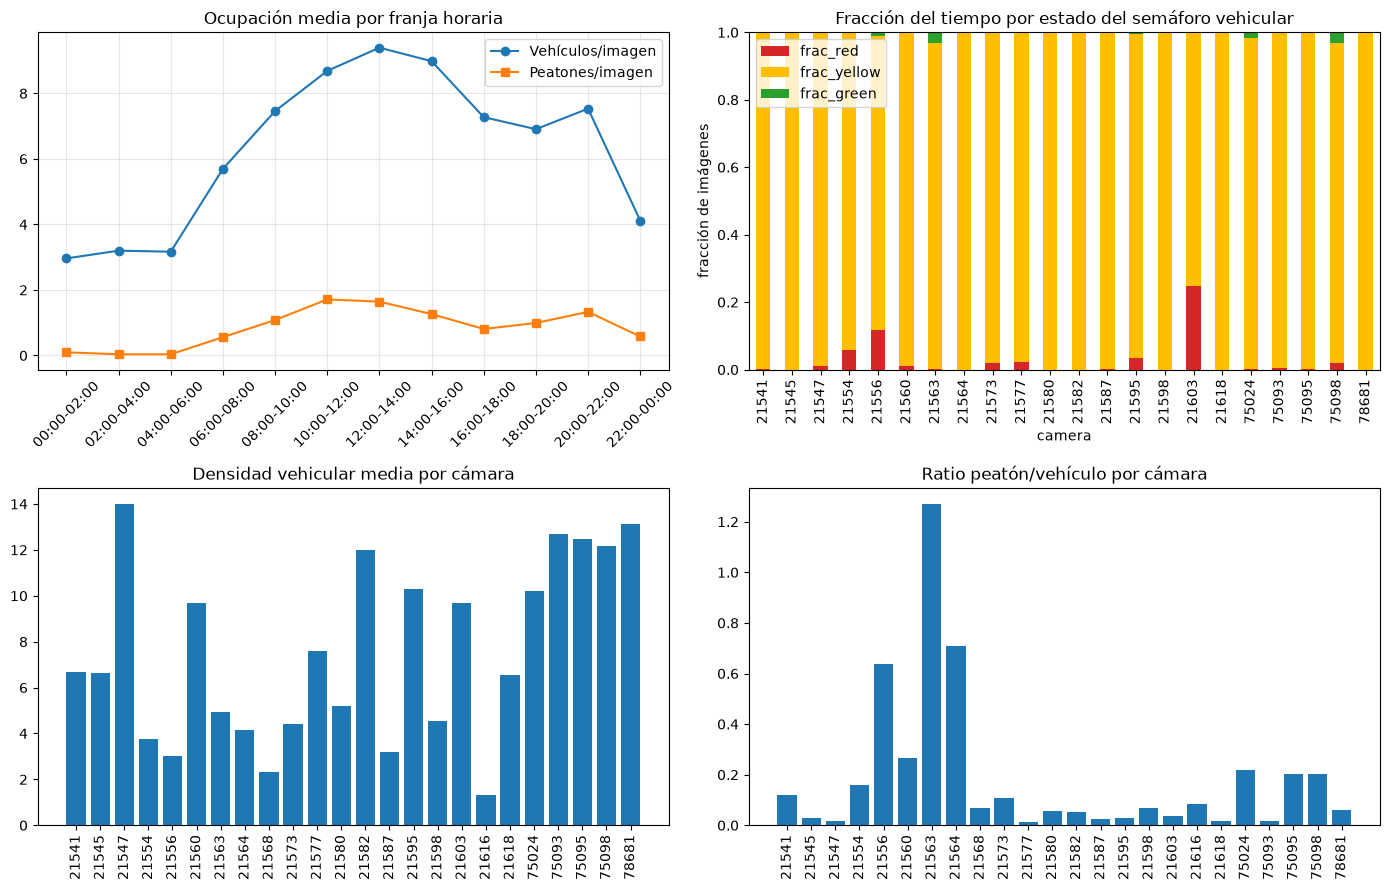

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(slot_df["time_slot_2h"], slot_df["vehiculos_medios_por_imagen"], marker="o", label="Vehículos/imagen")
axes[0, 0].plot(slot_df["time_slot_2h"], slot_df["peatones_medios_por_imagen"], marker="s", label="Peatones/imagen")
axes[0, 0].set_title("Ocupación media por franja horaria")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[0, 0].tick_params(axis="x", rotation=45)

fractions = camera_df.set_index("camera")[["frac_red", "frac_yellow", "frac_green"]].dropna(how="all")
if not fractions.empty:
    fractions.plot(kind="bar", stacked=True, color=["#d62728", "#ffbf00", "#2ca02c"], ax=axes[0, 1], legend=True)
axes[0, 1].set_title("Fracción del tiempo por estado del semáforo vehicular")
axes[0, 1].set_ylabel("fracción de imágenes")

axes[1, 0].bar(camera_df["camera"], camera_df["densidad_vehicular"])
axes[1, 0].set_title("Densidad vehicular media por cámara")
axes[1, 0].tick_params(axis="x", rotation=90)

axes[1, 1].bar(camera_df["camera"], camera_df["ratio_peaton_vehiculo"])
axes[1, 1].set_title("Ratio peatón/vehículo por cámara")
axes[1, 1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

### 6. Exportación de los indicadores

In [7]:
camera_df.to_csv(RESULTS_DIR / "indicadores_por_camara.csv", index=False)
slot_df.to_csv(RESULTS_DIR / "indicadores_por_franja.csv", index=False)
context_df.to_csv(RESULTS_DIR / "indicadores_por_contexto.csv", index=False)
print(f"Indicadores guardados en {RESULTS_DIR}")

Indicadores guardados en C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\resultados


## Salida / Resultados

| Salida | Contenido |
|---|---|
| `data/malaga/resultados/indicadores_por_camara.csv` | Indicadores de cada una de las 24 cámaras. |
| `data/malaga/resultados/indicadores_por_franja.csv` | Por franja horaria de 2 h. |
| `data/malaga/resultados/indicadores_por_contexto.csv` | Por tipo de día, iluminación y clima. |

**Última ejecución (24 cámaras, 74.236 fotogramas; refresco de 6 s → se calculan duraciones):**
- Media por cámara: 7,5 vehículos y 1,1 peatones por imagen (p90: 13 vehículos).
- Semáforo vehicular: no se detecta en el 80 % de los fotogramas. Cuando se detecta, la fracción de tiempo sale 97 % ámbar, 2,5 % rojo y 0,4 % verde.
- Duraciones: verde medio de 10,4 s con 0,33 fases medidas por cámara; ninguna fase roja completa medida.
- Contexto: 4,2 vehículos por imagen de noche frente a 8,2 de día; 9,2 en fin de semana frente a 7,0 en laborable.

## Observaciones

- **Los indicadores de estado del semáforo todavía no son válidos.** Dependen del color HSV de `02c`, muy sesgado hacia el ámbar. Hay que recalcularlos con el detector entrenado en `04`.
- Las duraciones de fase no son representativas: hay muy pocas rachas completas.
- La "cola" (`vehiculos_acumulados_rojo`) incluye los coches aparcados. Cuando `06` tenga zonas y validación, conviene descontar los vehículos `aparcado`.
- El fin de semana es un único sábado (17/10) y el clima solo tiene `sunny` y `unknown` (ver `02a` y `02b`): las comparaciones por contexto son orientativas.